# Análisis exploratorio (EDA) · Precio del petróleo Brent

**Caso de uso III · Aprendizaje automático**: predicción del Brent a corto (5 días hábiles), medio (63) y largo plazo (252) con RNN, LSTM y GRU.

El objetivo de este notebook es **entender los datos antes de modelar** y convertir lo que veamos en decisiones concretas para el preprocesamiento, el modelado, la aplicación y la presentación. Cada sección termina con una conclusión.

| # | Sección | Pregunta que responde |
|---|---|---|
| 1 | Calidad de los datos | ¿Qué filas y columnas son fiables? |
| 2 | El Brent y el ciclo económico | ¿Qué episodios explican la historia del precio? |
| 3 | Brent, WTI y futuros | ¿Por qué el Brent es el objetivo? ¿Qué hacemos con el WTI negativo? |
| 4 | Propiedades estadísticas | ¿Modelamos el precio o su variación? |
| 5 | Autocorrelación y memoria | ¿Cuánta historia necesita el modelo? ¿Cuánto se puede predecir? |
| 6 | Variables externas | ¿Qué variables aportan información? |
| 7 | Los tres horizontes | ¿Qué error comete el modelo ingenuo? ¿Qué incertidumbre hay? |
| 8 | Particiones temporales | ¿Cómo dividimos train, validación y test sin mezclar fechas? |
| 9 | Conclusiones | Decisiones que pasan al modelado |

Datos: `data/petroleo_dataset.csv`, generado con `scripts/download_data.py` (FRED + Yahoo Finance).

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.tsa.stattools import acf, adfuller

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

# Paleta fija (el color sigue a la serie, nunca al orden)
C = {
    "azul": "#2a78d6", "naranja": "#eb6834", "aqua": "#1baf7a", "amarillo": "#eda100",
    "magenta": "#e87ba4", "verde": "#008300", "violeta": "#6250d6", "rojo": "#e34948",
}
TINTA, TINTA_2, TINTA_SUAVE = "#0b0b0b", "#52514e", "#898781"
REJILLA, EJE, FONDO = "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 110,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": TINTA, "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE,
    "lines.linewidth": 1.4, "legend.frameon": False,
})


def eje_años(ax, cada=2):
    """Eje X con un rótulo cada `cada` años."""
    ax.xaxis.set_major_locator(mdates.YearLocator(cada))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


# El notebook puede ejecutarse desde la raíz del repo o desde notebooks/
RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RUTA_DATOS = RAIZ / "data" / "petroleo_dataset.csv"
HORIZONTES = {"Corto (5 días)": 5, "Medio (63 días)": 63, "Largo (252 días)": 252}

In [2]:
df = pd.read_csv(RUTA_DATOS, parse_dates=["Date"], index_col="Date")
print(f"{df.shape[0]:,} filas x {df.shape[1]} columnas | "
      f"{df.index.min():%d/%m/%Y} → {df.index.max():%d/%m/%Y}")
df.head()

7,003 filas x 20 columnas | 04/01/2000 → 05/11/2026


,brent,wti,gas_natural,tipo_bce,usd_por_eur,cny_por_usd,vix,brent_fut_Open,brent_fut_High,brent_fut_Low,brent_fut_Close,brent_fut_Volume,wti_fut_Open,wti_fut_High,wti_fut_Low,wti_fut_Close,wti_fut_Volume,indice_dolar,oro,cobre
Date,,,,,,,,,,,,,,,,,,,,
2000-01-04,23.95,25.56,NaN,2.00,1.03,8.28,27.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.41,NaN,NaN
2000-01-05,23.72,24.65,NaN,2.00,1.03,8.28,26.41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.38,NaN,NaN
2000-01-06,23.55,24.79,NaN,2.00,1.03,8.28,25.73,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.65,NaN,NaN
2000-01-07,23.35,24.79,NaN,2.00,1.03,8.28,21.72,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.80,NaN,NaN
2000-01-10,22.77,24.71,2.20,2.00,1.03,8.28,21.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.99,NaN,NaN


## 1. Calidad e integridad de los datos

El script de descarga une todas las fuentes, **rellena los huecos con el último valor disponible** y se queda con los días laborables. Antes de analizar nada conviene saber qué hay detrás de cada fila.

### 1.1 Cobertura de cada serie

In [3]:
FRED = ["brent", "wti", "gas_natural", "tipo_bce", "usd_por_eur", "cny_por_usd", "vix"]
cobertura = pd.DataFrame({
    "fuente": ["FRED" if c in FRED else "Yahoo Finance" for c in df.columns],
    "primer dato": [df[c].first_valid_index().date() for c in df.columns],
    "nulos": df.isna().sum().values,
    "% nulos": (df.isna().mean().values * 100).round(1),
}, index=df.columns)
cobertura

,fuente,primer dato,nulos,% nulos
brent,FRED,2000-01-04,0,0.00
wti,FRED,2000-01-04,0,0.00
gas_natural,FRED,2000-01-10,4,0.10
tipo_bce,FRED,2000-01-04,0,0.00
usd_por_eur,FRED,2000-01-04,0,0.00
cny_por_usd,FRED,2000-01-04,0,0.00
vix,FRED,2000-01-04,0,0.00
brent_fut_Open,Yahoo Finance,2007-07-30,1974,28.20
brent_fut_High,Yahoo Finance,2007-07-30,1974,28.20
brent_fut_Low,Yahoo Finance,2007-07-30,1974,28.20


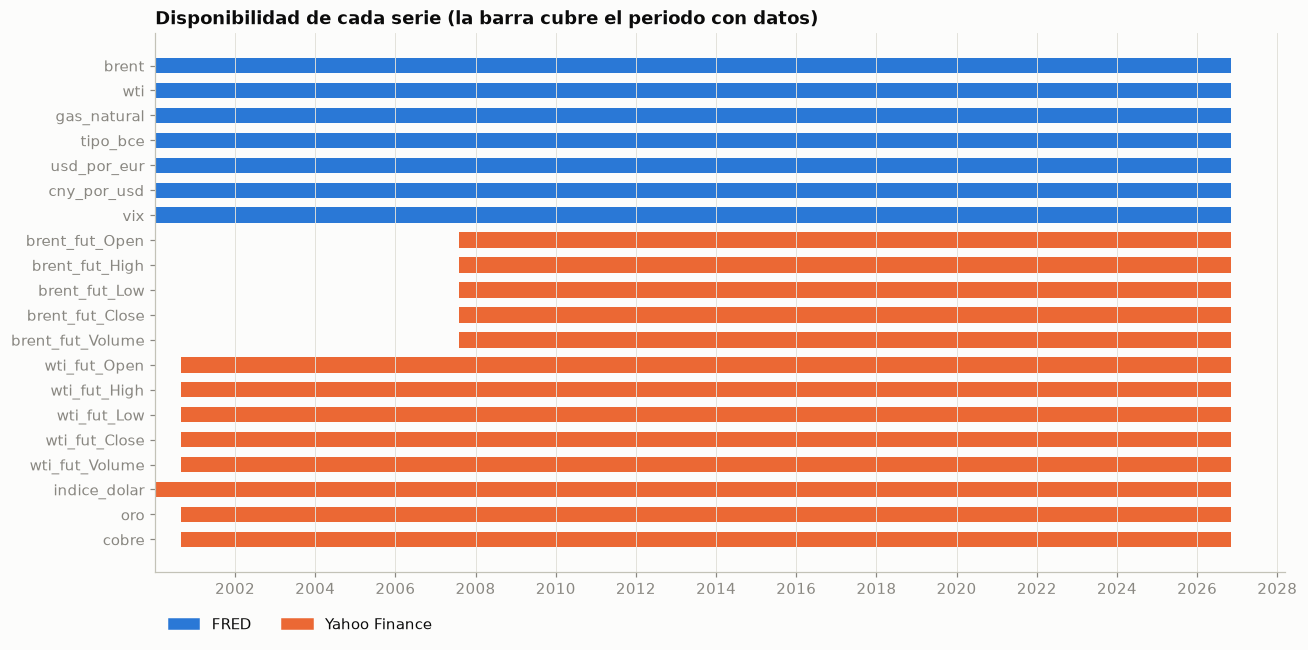

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))
color_fuente = {"FRED": C["azul"], "Yahoo Finance": C["naranja"]}
fin = mdates.date2num(df.index.max())
for i, col in enumerate(cobertura.index[::-1]):
    ini = mdates.date2num(pd.Timestamp(cobertura.loc[col, "primer dato"]))
    ax.barh(i, fin - ini, left=ini, height=0.62, color=color_fuente[cobertura.loc[col, "fuente"]])
ax.set_yticks(range(len(cobertura)), cobertura.index[::-1])
ax.xaxis_date()
eje_años(ax)
ax.grid(axis="y", visible=False)
ax.set_title("Disponibilidad de cada serie (la barra cubre el periodo con datos)")
marcas = [plt.Rectangle((0, 0), 1, 1, color=v) for v in color_fuente.values()]
ax.legend(marcas, color_fuente.keys(), ncol=2, loc="upper left", bbox_to_anchor=(0, -0.06))
plt.tight_layout()
plt.show()

### 1.2 Días en que el Brent no cotizó

Como el relleno se hace sobre la unión de calendarios, en los festivos del Brent aparece una fila con **el precio del día anterior repetido**. Esas filas no son observaciones reales: introducen rentabilidades de 0 % artificiales y alargan el calendario.

In [5]:
repetido = df["brent"].diff().eq(0)
print(f"Filas con el Brent idéntico al día anterior: {repetido.sum()} de {len(df):,} ({repetido.mean():.1%})")
print("\nFechas (día-mes) que más se repiten:")
print(pd.Series(df.index[repetido].strftime("%d-%m")).value_counts().head(8).to_string())

Filas con el Brent idéntico al día anterior: 572 de 7,003 (8.2%)

Fechas (día-mes) que más se repiten:
Date
25-12    19
01-01    19
26-12    15
27-12     7
04-07     7
29-03     6
31-08     6
30-03     5


In [6]:
# Comprobación con FRED (necesita conexión): ¿qué filas son días reales de cotización del Brent?
# Sin conexión se usa la regla "precio repetido = día sin cotización", que también descarta
# los pocos empates reales.
try:
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DCOILBRENTEU&cosd=2000-01-01"
    fred_brent = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0].dropna()
    es_dia_brent = df.index.isin(fred_brent.index)
    print(f"Días reales de cotización del Brent en el CSV: {es_dia_brent.sum():,}")
    print(f"Filas rellenadas (el Brent no cotizó):        {(~es_dia_brent).sum():,}"
          f"  → todas con el precio repetido: {repetido[~es_dia_brent].all()}")
    print(f"Repeticiones que son empates reales:          {(repetido & es_dia_brent).sum():,}")
except Exception as error:
    es_dia_brent = ~repetido.values
    print("Sin conexión con FRED: se usa la regla del precio repetido.", error)

Días reales de cotización del Brent en el CSV: 6,501
Filas rellenadas (el Brent no cotizó):        502  → todas con el precio repetido: True
Repeticiones que son empates reales:          70


### 1.3 Las últimas filas

In [7]:
ultimo_real = df.index[es_dia_brent][-1]
print(f"Último dato real del Brent: {ultimo_real:%d/%m/%Y} → {df.loc[ultimo_real, 'brent']:.2f} $/barril")
(df.tail(5)[["brent", "wti", "brent_fut_Close", "wti_fut_Close", "vix"]]
   .assign(**{"¿cotizó el Brent?": np.where(es_dia_brent[-5:], "sí", "no (relleno)")}))

Último dato real del Brent: 03/11/2026 → 107.03 $/barril


,brent,wti,brent_fut_Close,wti_fut_Close,vix,¿cotizó el Brent?
Date,,,,,,
2026-10-30,120.15,107.56,117.64,104.12,19.42,sí
2026-11-02,107.39,100.06,104.77,96.46,21.15,sí
2026-11-03,107.03,99.64,103.60,96.09,20.83,sí
2026-11-04,107.03,99.64,94.62,88.12,16.61,no (relleno)
2026-11-05,107.03,99.64,94.62,88.12,16.61,no (relleno)


In [8]:
filas_año = pd.DataFrame({
    "filas del CSV": df.groupby(df.index.year).size(),
    "días reales del Brent": df[es_dia_brent].groupby(df.index[es_dia_brent].year).size(),
})
print("Media por año completo (2001-2025):")
print(filas_año.loc[2001:2025].mean().round(1).to_string())

# Tabla de trabajo: solo los días en que el Brent cotizó
dfb = df[es_dia_brent].copy()
print(f"\nTabla de trabajo `dfb`: {len(dfb):,} días de cotización del Brent")

Media por año completo (2001-2025):
filas del CSV           260.90
días reales del Brent   243.40

Tabla de trabajo `dfb`: 6,501 días de cotización del Brent


> ### Conclusión de la sección 1
> - Las series de **FRED están completas desde 2000**. Las de Yahoo empiezan más tarde: futuros del WTI, oro y cobre en agosto de 2000 y **futuros del Brent en julio de 2007** (28 % de huecos).
> - **502 filas (7,2 %) no son días de cotización del Brent**: son festivos (Navidad, Año Nuevo, 4 de julio, Semana Santa…) con el precio del día anterior. Otras 70 repeticiones son empates reales y se conservan.
> - **Las dos últimas filas son copias** (la EIA publica con unos días de retraso): el último Brent real es el del **03/11/2026, 107,03 $**.
> - El Brent cotiza **~243 días al año**; el CSV tiene ~261 filas al año porque mezcla calendarios.
>
> **Decisión:** trabajar con el **calendario real del Brent** (6.501 días) y usar como «último precio» el último dato real. En el preprocesamiento conviene marcar los días de cotización al descargar, en lugar de depender de esta comprobación con FRED.

## 2. La serie del Brent y el ciclo económico

La aplicación debe marcar los principales picos y caídas y explicarlos. Aquí se localizan **a partir de los datos** (máximo o mínimo dentro de cada ventana) para que fechas y precios sean exactos.

In [9]:
brent = dfb["brent"]

EVENTOS = [
    dict(nombre="Máximo histórico", ini="2008-01-01", fin="2008-12-31", tipo="max",
         causa="Superciclo de materias primas: demanda de China y emergentes, oferta ajustada "
               "y fuerte entrada de inversión financiera."),
    dict(nombre="Desplome por la crisis financiera", ini="2008-07-01", fin="2009-06-30", tipo="min",
         causa="Quiebra de Lehman Brothers (sept. 2008) y recesión mundial: la demanda de crudo se hunde."),
    dict(nombre="Máximo de 2011-2012 (Libia e Irán)", ini="2011-01-01", fin="2012-12-31", tipo="max",
         causa="Guerra de Libia (2011) y sanciones y embargo al crudo de Irán (2012) retiran oferta; "
               "el Brent se mantiene por encima de 100 $ hasta mediados de 2014."),
    dict(nombre="Inicio de la caída por exceso de oferta", ini="2014-01-01", fin="2014-12-31", tipo="max",
         causa="Boom del petróleo de esquisto en EE. UU.; en nov. 2014 la OPEP decide no recortar."),
    dict(nombre="Fondo del exceso de oferta", ini="2015-06-01", fin="2016-12-31", tipo="min",
         causa="Exceso de oferta mundial y vuelta de Irán al mercado; a finales de 2016 la OPEP+ "
               "pacta recortes de producción."),
    dict(nombre="Desplome por la pandemia", ini="2020-01-01", fin="2020-12-31", tipo="min",
         causa="Confinamientos por la COVID-19 y guerra de precios Arabia Saudí–Rusia: la demanda "
               "se hunde y los almacenes se llenan."),
    dict(nombre="Subida tras la invasión de Ucrania", ini="2022-01-01", fin="2022-12-31", tipo="max",
         causa="Invasión rusa de Ucrania (24-feb-2022) y sanciones a uno de los mayores exportadores."),
    dict(nombre="Pico de 2026", ini="2026-01-01", fin="2026-12-31", tipo="max",
         causa="Pendiente de documentar con fuentes de 2026."),
]

filas = []
for ev in EVENTOS:
    tramo = brent.loc[ev["ini"]:ev["fin"]]
    fecha = tramo.idxmax() if ev["tipo"] == "max" else tramo.idxmin()
    filas.append({"evento": ev["nombre"], "fecha": fecha, "precio ($)": brent[fecha],
                  "tipo": "pico" if ev["tipo"] == "max" else "caída", "causa": ev["causa"]})
filas.append({"evento": "Último dato", "fecha": brent.index[-1], "precio ($)": brent.iloc[-1],
              "tipo": "actual", "causa": "Último precio publicado por la EIA."})

eventos = pd.DataFrame(filas)
eventos.index = range(1, len(eventos) + 1)
eventos.insert(3, "vs. evento anterior",
               eventos["precio ($)"].pct_change().map(lambda v: "" if pd.isna(v) else f"{v:+.0%}"))
eventos.assign(fecha=eventos["fecha"].dt.strftime("%d/%m/%Y"))

,evento,fecha,precio ($),vs. evento anterior,tipo,causa
1,Máximo histórico,03/07/2008,143.95,,pico,Superciclo de materias primas: demanda de Chin...
2,Desplome por la crisis financiera,26/12/2008,33.73,-77%,caída,Quiebra de Lehman Brothers (sept. 2008) y rece...
3,Máximo de 2011-2012 (Libia e Irán),13/03/2012,128.14,+280%,pico,Guerra de Libia (2011) y sanciones y embargo a...
4,Inicio de la caída por exceso de oferta,19/06/2014,115.19,-10%,pico,Boom del petróleo de esquisto en EE. UU.; en n...
5,Fondo del exceso de oferta,20/01/2016,26.01,-77%,caída,Exceso de oferta mundial y vuelta de Irán al m...
6,Desplome por la pandemia,21/04/2020,9.12,-65%,caída,Confinamientos por la COVID-19 y guerra de pre...
7,Subida tras la invasión de Ucrania,08/03/2022,133.18,+1360%,pico,Invasión rusa de Ucrania (24-feb-2022) y sanci...
8,Pico de 2026,07/04/2026,138.21,+4%,pico,Pendiente de documentar con fuentes de 2026.
9,Último dato,03/11/2026,107.03,-23%,actual,Último precio publicado por la EIA.


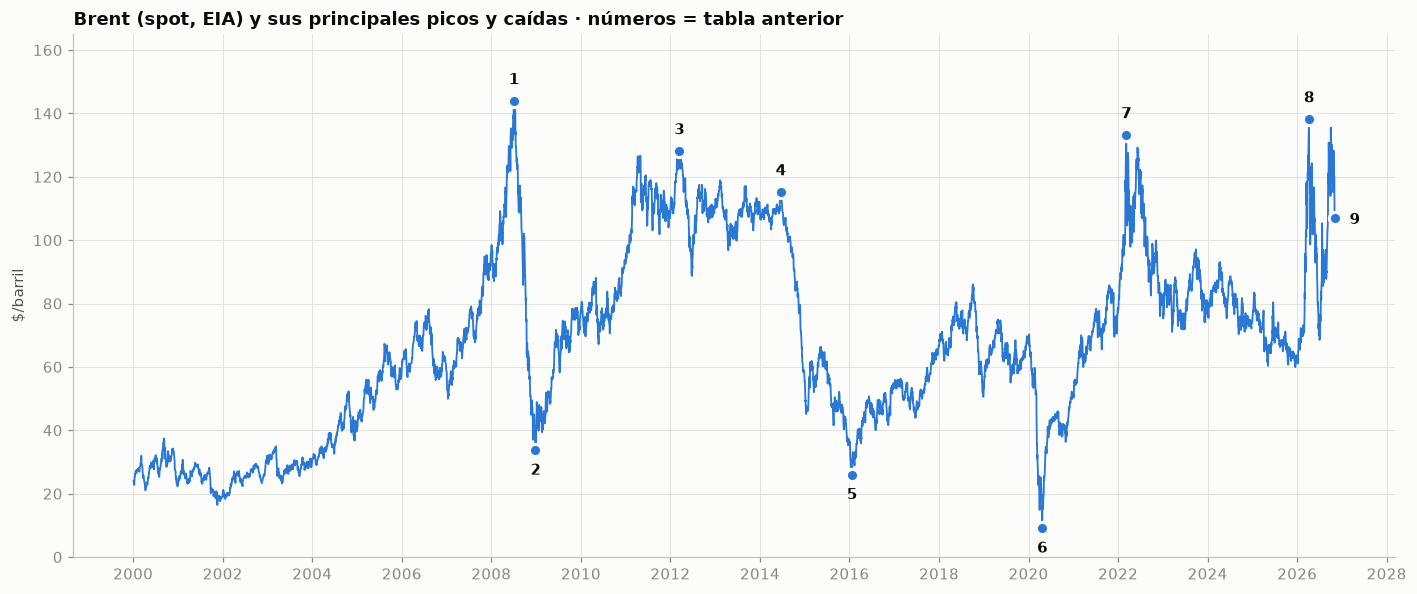

In [10]:
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(brent.index, brent, color=C["azul"], lw=1.2)
for n, ev in eventos.iterrows():
    desplazamiento = {"pico": (0, 11), "caída": (0, -16), "actual": (13, -4)}[ev["tipo"]]
    ax.plot(ev["fecha"], ev["precio ($)"], "o", ms=8, color=C["azul"], mec=FONDO, mew=2)
    ax.annotate(f"{n}", (ev["fecha"], ev["precio ($)"]), xytext=desplazamiento,
                textcoords="offset points", ha="center", fontsize=10, fontweight="bold", color=TINTA)
ax.set_ylabel("$/barril")
ax.set_ylim(0, 165)
eje_años(ax)
ax.set_title("Brent (spot, EIA) y sus principales picos y caídas · números = tabla anterior")
plt.tight_layout()
plt.show()

> ### Conclusión de la sección 2
> - **2008:** de 143,95 $ (03/07) a 33,73 $ (26/12): **−77 % en menos de seis meses**.
> - **2011-2014:** meseta por encima de 100 $ (máximo de 128,14 $ en marzo de 2012).
> - **2014-2016:** de 115,19 $ a 26,01 $ (**−77 %**) por exceso de oferta.
> - **2020:** mínimo de toda la serie, **9,12 $** (21/04/2020).
> - **2022:** 133,18 $ (08/03/2022) tras la invasión de Ucrania.
> - **2026:** **138,21 $ (07/04/2026)**, el segundo máximo de la serie; el último dato (107,03 $) está un 23 % por debajo.
>
> El precio pasa por **regímenes muy distintos** y los grandes cambios los provocan **sucesos externos** (crisis financiera, guerras, decisiones de la OPEP+, pandemia) que no están en los datos. Ningún modelo puede anticiparlos, y la aplicación debe decirlo al explicar qué puede invalidar una predicción.
>
> **Decisión:** reutilizar la tabla `EVENTOS` en la aplicación (marcas del gráfico y textos). **Pendiente:** documentar la causa del pico de 2026 con fuentes actuales.

## 3. Brent, WTI y futuros

### 3.1 Brent frente a WTI

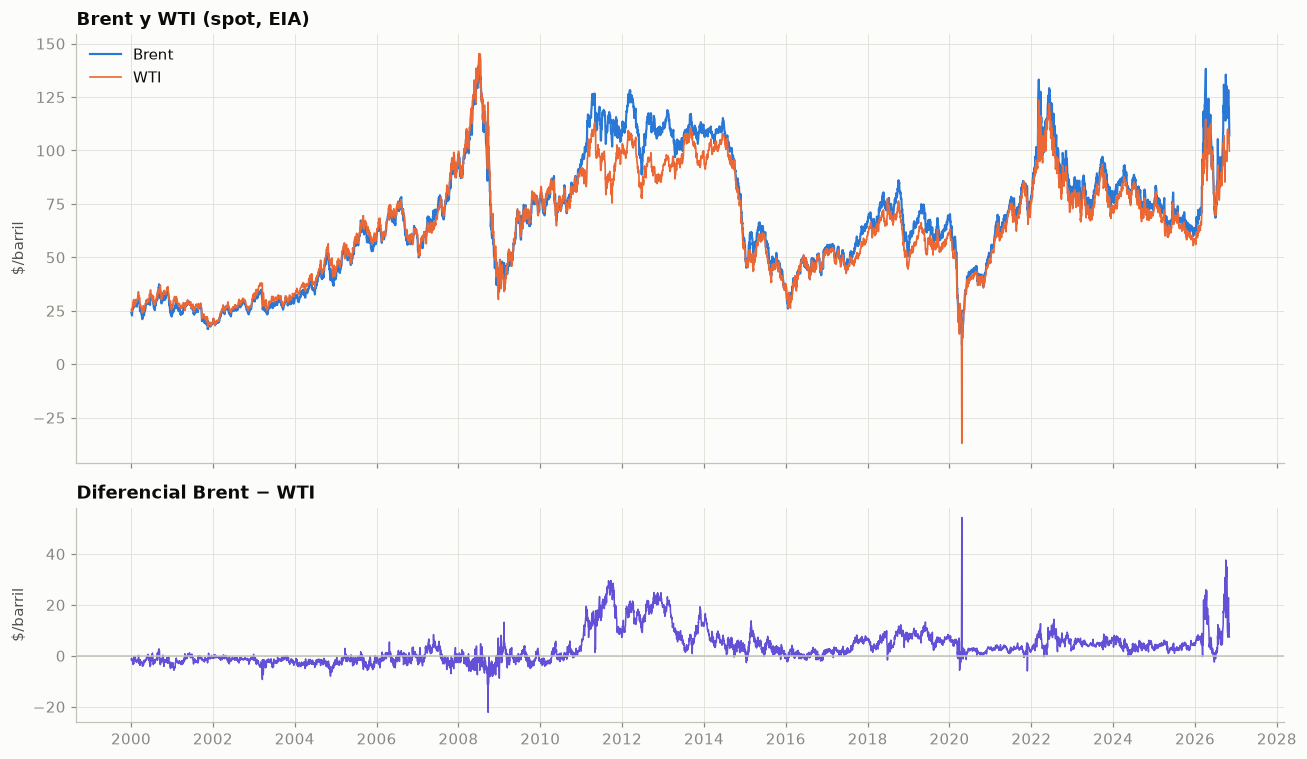

Correlación de niveles:          0.981
Correlación de variaciones (log): 0.622

Diferencial medio Brent − WTI por periodo ($/barril):
2000-2010   -1.38
2011-2015   10.75
2016-2020    3.94
2021-2026    5.05


In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(dfb.index, dfb["brent"], color=C["azul"], label="Brent")
ax1.plot(dfb.index, dfb["wti"], color=C["naranja"], lw=1.1, label="WTI")
ax1.set_ylabel("$/barril")
ax1.legend(loc="upper left")
ax1.set_title("Brent y WTI (spot, EIA)")
diferencial = dfb["brent"] - dfb["wti"]
ax2.plot(diferencial.index, diferencial, color=C["violeta"], lw=1)
ax2.axhline(0, color=EJE, lw=1)
ax2.set_ylabel("$/barril")
ax2.set_title("Diferencial Brent − WTI")
eje_años(ax2)
plt.tight_layout()
plt.show()

positivos = dfb[["brent", "wti"]].where(dfb[["brent", "wti"]] > 0)
print(f"Correlación de niveles:          {dfb['brent'].corr(dfb['wti']):.3f}")
print(f"Correlación de variaciones (log): {np.log(positivos).diff().corr().iloc[0, 1]:.3f}")
print("\nDiferencial medio Brent − WTI por periodo ($/barril):")
print(diferencial.groupby(pd.cut(diferencial.index.year, [1999, 2010, 2015, 2020, 2026],
                                 labels=["2000-2010", "2011-2015", "2016-2020", "2021-2026"]),
                          observed=True).mean().round(2).to_string())

### 3.2 El WTI negativo (20/04/2020)

In [12]:
dfb.loc["2020-04-15":"2020-04-24", ["brent", "wti", "wti_fut_Close"]]

,brent,wti,wti_fut_Close
Date,,,
2020-04-15,19.80,19.96,19.87
2020-04-16,18.69,19.82,19.87
2020-04-17,19.75,18.31,18.27
2020-04-20,17.36,-36.98,-37.63
2020-04-21,9.12,8.91,10.01
2020-04-22,13.77,13.64,13.78
2020-04-23,15.06,15.06,16.50
2020-04-24,15.87,15.99,16.94


### 3.3 Brent spot (EIA) frente al futuro (Yahoo)

El **spot** de la EIA es el precio de cargamentos físicos en Londres; el **futuro** (BZ=F) es el contrato del mes siguiente que cotiza en el mercado ICE. Suelen moverse juntos, pero no son el mismo precio.

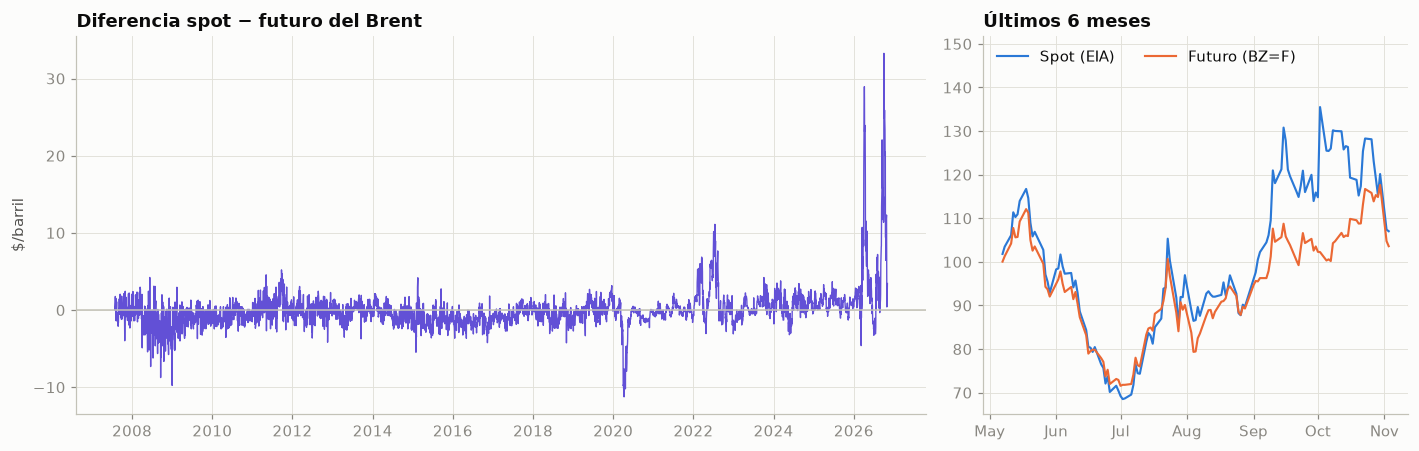

Correlación de variaciones diarias spot/futuro: 0.747
Diferencia media absoluta: 1.40 $ | días con más de 5 $ de diferencia: 3.5%
Último día común (03/11/2026): spot 107.03 $ | futuro 103.60 $


In [13]:
sf = dfb.loc["2007-07-30":, ["brent", "brent_fut_Close"]].dropna()
base = sf["brent"] - sf["brent_fut_Close"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(base.index, base, color=C["violeta"], lw=0.9)
axes[0].axhline(0, color=EJE, lw=1)
axes[0].set_ylabel("$/barril")
axes[0].set_title("Diferencia spot − futuro del Brent")
eje_años(axes[0])
reciente = sf.loc[sf.index.max() - pd.Timedelta(days=180):]
axes[1].plot(reciente.index, reciente["brent"], color=C["azul"], label="Spot (EIA)")
axes[1].plot(reciente.index, reciente["brent_fut_Close"], color=C["naranja"], label="Futuro (BZ=F)")
axes[1].set_ylim(reciente.min().min() * 0.95, reciente.max().max() * 1.12)
axes[1].legend(loc="upper left", ncol=2)
axes[1].set_title("Últimos 6 meses")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout()
plt.show()

print(f"Correlación de variaciones diarias spot/futuro: "
      f"{np.log(sf).diff().corr().iloc[0, 1]:.3f}")
print(f"Diferencia media absoluta: {base.abs().mean():.2f} $ | "
      f"días con más de 5 $ de diferencia: {(base.abs() > 5).mean():.1%}")
print(f"Último día común ({sf.index[-1]:%d/%m/%Y}): spot {sf['brent'].iloc[-1]:.2f} $ | "
      f"futuro {sf['brent_fut_Close'].iloc[-1]:.2f} $")

> ### Conclusión de la sección 3
> - Brent y WTI se mueven juntos (correlación de niveles 0,98; de variaciones diarias 0,62), pero el **diferencial cambia según el periodo**: ≈ −1 $ en 2000-2010, ≈ 11 $ en 2011-2015 y 4-5 $ después, con picos de más de 30 $ en 2026.
> - El **WTI negativo** (−36,98 $ spot, −37,63 $ futuro) fue un problema de almacenamiento en EE. UU. al vencer el contrato de mayo; ese día el Brent cerró en 17,36 $ y su mínimo, al día siguiente, fue de 9,12 $. Es el principal motivo para usar el **Brent como objetivo**.
> - Spot (EIA) y futuro (Yahoo) son casi equivalentes en calma (diferencia media de 1,4 $), pero se separan en momentos de tensión (más de 30 $ en 2026). La gran distancia que vimos en la última fila (107 $ frente a 94,6 $) se debía sobre todo a que el spot de esa fila era un relleno; el último día común la diferencia es de 3,4 $.
>
> **Decisión:** objetivo = **Brent spot de la EIA**, como pide el enunciado. El WTI entra como variable explicativa, tratando el 20/04/2020 (sustituirlo por el valor anterior) para que no distorsione el escalado.

## 4. Propiedades estadísticas de la serie

### 4.1 Precio, variación diaria y volatilidad

La variación diaria se mide como **rentabilidad logarítmica**: $r_t = \ln(P_t / P_{t-1})$, que para cambios pequeños equivale al porcentaje de variación.

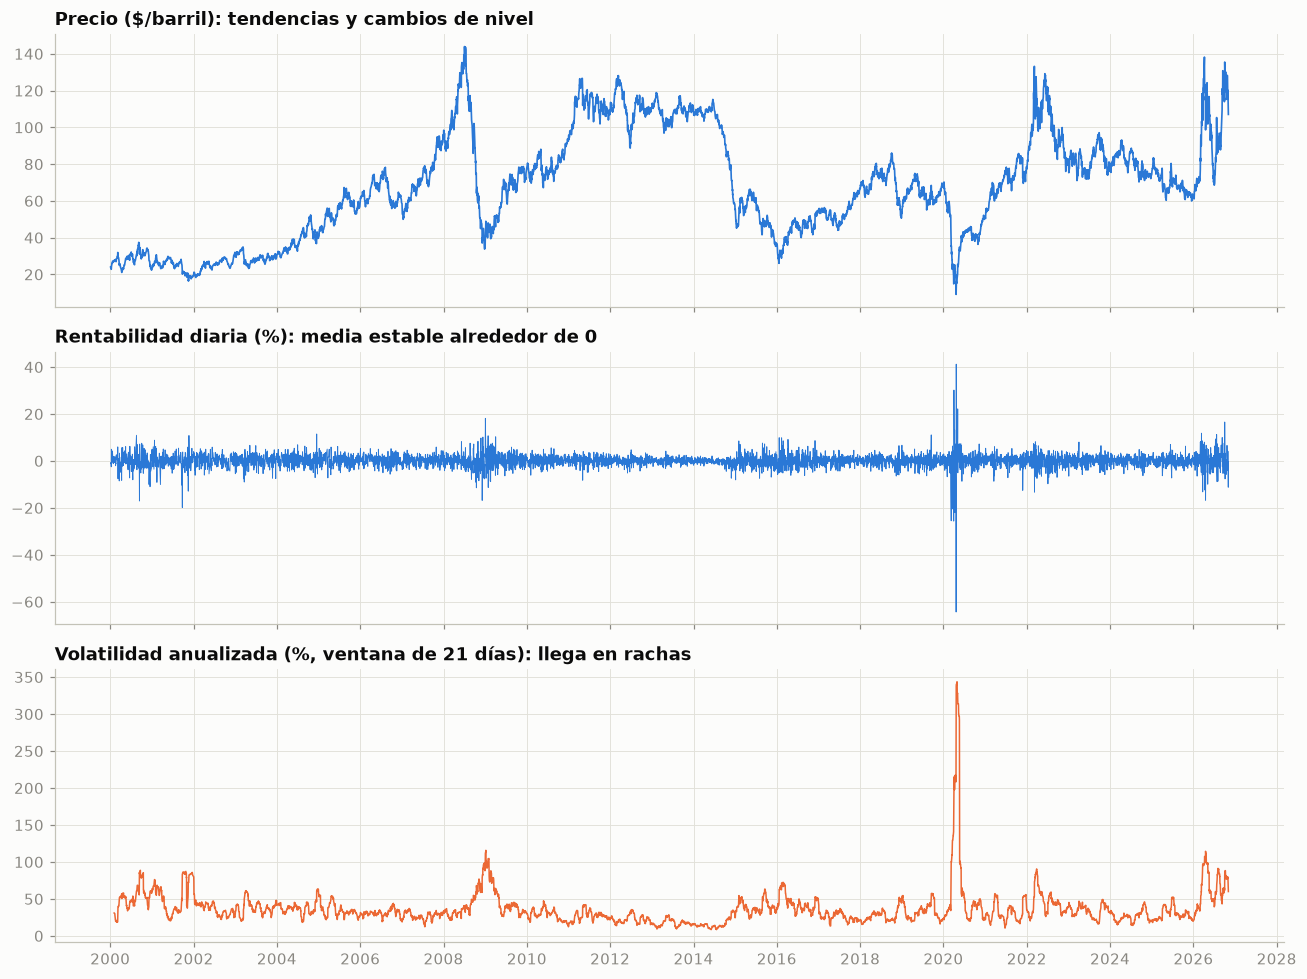

In [14]:
ret = np.log(brent).diff().dropna()
volatilidad = ret.rolling(21).std() * np.sqrt(252)   # anualizada, ventana de un mes

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(brent.index, brent, color=C["azul"], lw=1.1)
axes[0].set_title("Precio ($/barril): tendencias y cambios de nivel")
axes[1].plot(ret.index, ret * 100, color=C["azul"], lw=0.6)
axes[1].set_title("Rentabilidad diaria (%): media estable alrededor de 0")
axes[2].plot(volatilidad.index, volatilidad * 100, color=C["naranja"], lw=1)
axes[2].set_title("Volatilidad anualizada (%, ventana de 21 días): llega en rachas")
eje_años(axes[2])
plt.tight_layout()
plt.show()

### 4.2 Estacionariedad (test de Dickey-Fuller aumentado)

Hipótesis nula: la serie **no** es estacionaria. Un p-valor < 0,05 permite rechazarla.

In [15]:
def test_adf(serie):
    estadistico, p_valor, *_ = adfuller(serie.dropna(), autolag="AIC", result_object=False)
    return {"estadístico ADF": estadistico, "p-valor": round(p_valor, 4),
            "¿estacionaria (5 %)?": "sí" if p_valor < 0.05 else "no"}

pd.DataFrame({"precio": test_adf(brent),
              "log(precio)": test_adf(np.log(brent)),
              "rentabilidad diaria": test_adf(ret)}).T

,estadístico ADF,p-valor,¿estacionaria (5 %)?
precio,-2.83,0.05,no
log(precio),-2.81,0.06,no
rentabilidad diaria,-14.10,0.00,sí


### 4.3 Distribución de las variaciones diarias

Media diaria: 0.00023 | desviación típica: 0.0274 (≈ 44% anual)
Asimetría: -1.73 | curtosis en exceso: 63.7 (normal = 0)
Días con |variación| > 3σ: 1.17% (normal: 0,27 %)


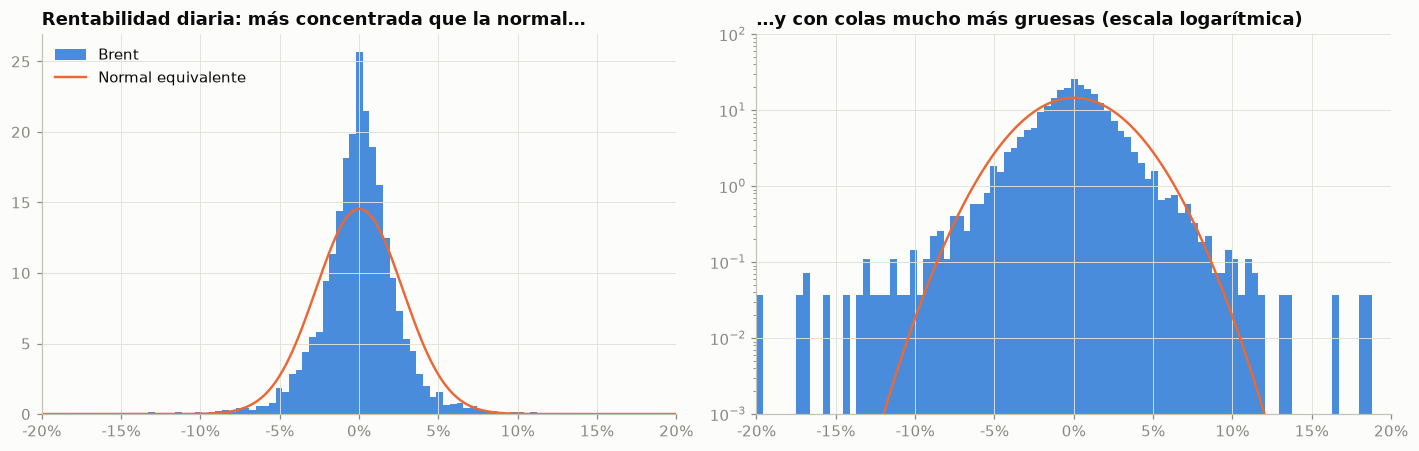

In [16]:
mu, sigma = ret.mean(), ret.std()
print(f"Media diaria: {mu:.5f} | desviación típica: {sigma:.4f} (≈ {sigma * np.sqrt(252):.0%} anual)")
print(f"Asimetría: {stats.skew(ret):.2f} | curtosis en exceso: {stats.kurtosis(ret):.1f} (normal = 0)")
print(f"Días con |variación| > 3σ: {(ret.abs() > 3 * sigma).mean():.2%} (normal: 0,27 %)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.linspace(-0.2, 0.2, 400)
for ax, escala in zip(axes, ["linear", "log"]):
    ax.hist(ret, bins=250, density=True, color=C["azul"], alpha=0.85, label="Brent")
    ax.plot(x, stats.norm.pdf(x, mu, sigma), color=C["naranja"], lw=1.6, label="Normal equivalente")
    ax.set_yscale(escala)
    ax.set_xlim(-0.2, 0.2)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_title("Rentabilidad diaria: más concentrada que la normal…")
axes[1].set_title("…y con colas mucho más gruesas (escala logarítmica)")
axes[1].set_ylim(1e-3, None)
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

In [17]:
mayores = ret.abs().nlargest(8).index
pd.DataFrame({"precio anterior": brent.shift(1)[mayores], "precio": brent[mayores],
              "variación": (np.exp(ret[mayores]) - 1).map("{:+.1%}".format)}).sort_index()

,precio anterior,precio,variación
Date,,,
2020-03-09,45.60,35.33,-22.5%
2020-03-18,27.97,22.79,-18.5%
2020-03-31,19.19,14.85,-22.6%
2020-04-02,14.97,20.24,+35.2%
2020-04-09,25.22,20.23,-19.8%
2020-04-21,17.36,9.12,-47.5%
2020-04-22,9.12,13.77,+51.0%
2020-05-05,20.40,25.46,+24.8%


> ### Conclusión de la sección 4
> - El **precio no es estacionario** (ADF, p ≈ 0,05): sube y baja por regímenes. La **variación diaria sí lo es** (p < 0,01).
> - La variación diaria tiene media ≈ 0 y una volatilidad del ≈ 44 % anual, con **colas muy gruesas**: curtosis en exceso de 64 y un 1,2 % de días con movimientos de más de 3σ (más de 4 veces lo esperable en una normal). Los 8 mayores movimientos son de marzo-mayo de 2020 (hasta −47,5 % y +51 % en un día).
> - La **volatilidad llega en rachas** (2008, 2020, 2022, 2026): va de ≈ 10 % a más del 300 % anual.
>
> **Decisiones:**
> - La red **predecirá la variación** (rentabilidad logarítmica a *h* días) y no el nivel. Es estacionaria, no obliga a extrapolar precios fuera del rango de entrenamiento y hace que «predecir 0» sea exactamente el modelo ingenuo. El precio se reconstruye después: $\hat P_{t+h} = P_t \cdot e^{\hat r}$.
> - Limitar el peso de los extremos de 2020: recortar cada variable de entrada entre sus percentiles 1 y 99 (calculados **solo con train**) y entrenar con **pérdida Huber**. La evaluación se hace sobre los datos reales, sin recortar.
> - La incertidumbre no puede suponer normalidad: mejor **intervalos empíricos** (cuantiles de los errores).

## 5. Autocorrelación y memoria

La autocorrelación mide cuánto se parece la serie a sí misma desplazada $k$ días. La banda gris marca el umbral de significación (95 %).

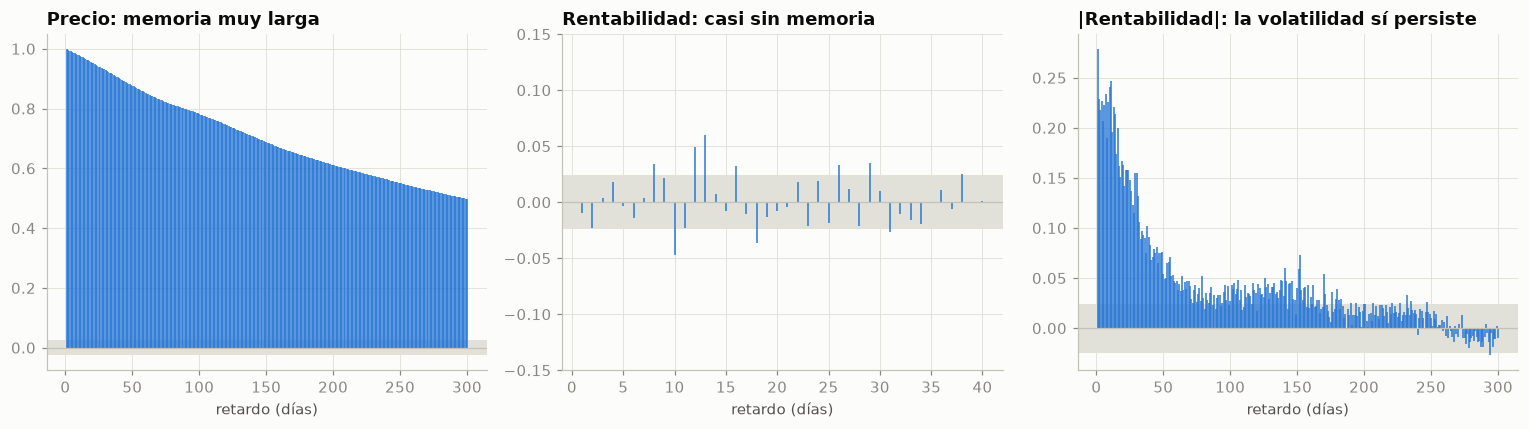

ACF del precio a 60 / 252 días: 0.85 / 0.55
ACF de la rentabilidad, retardos 1-5: [-0.01  -0.023  0.004  0.018 -0.003]
Retardos 1-40 significativos en la rentabilidad: 10 de 40 (por azar se esperarían ~2)
ACF de |rentabilidad| a 60 días: 0.05


In [18]:
def dibujar_acf(ax, serie, retardos, titulo):
    valores = acf(serie.dropna(), nlags=retardos, fft=True)
    banda = 1.96 / np.sqrt(serie.dropna().size)
    ax.axhspan(-banda, banda, color=REJILLA, lw=0)
    ax.vlines(range(1, retardos + 1), 0, valores[1:], color=C["azul"], lw=1)
    ax.axhline(0, color=EJE, lw=0.8)
    ax.set_title(titulo)
    ax.set_xlabel("retardo (días)")
    return valores

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
acf_precio = dibujar_acf(axes[0], brent, 300, "Precio: memoria muy larga")
acf_ret = dibujar_acf(axes[1], ret, 40, "Rentabilidad: casi sin memoria")
acf_abs = dibujar_acf(axes[2], ret.abs(), 300, "|Rentabilidad|: la volatilidad sí persiste")
axes[1].set_ylim(-0.15, 0.15)
plt.tight_layout()
plt.show()

banda = 1.96 / np.sqrt(len(ret))
print(f"ACF del precio a 60 / 252 días: {acf_precio[60]:.2f} / {acf_precio[252]:.2f}")
print(f"ACF de la rentabilidad, retardos 1-5: {np.round(acf_ret[1:6], 3)}")
print(f"Retardos 1-40 significativos en la rentabilidad: {(np.abs(acf_ret[1:]) > banda).sum()} de 40 "
      f"(por azar se esperarían ~2)")
print(f"ACF de |rentabilidad| a 60 días: {acf_abs[60]:.2f}")

> ### Conclusión de la sección 5
> - **Precio:** autocorrelación de 0,85 a 60 días y 0,55 a 252. Es la inercia del nivel, no capacidad de predicción.
> - **Variación diaria:** autocorrelaciones minúsculas (|ρ| < 0,06). Aunque 10 de 40 retardos superan la banda, su tamaño es irrelevante para predecir y en parte se debe a las colas gruesas. **El pasado del Brent apenas anticipa su variación**, así que el modelo ingenuo será difícil de batir.
> - **|Variación|:** autocorrelación de 0,2-0,28 los primeros días, que se desvanece hacia los 60 días: **la volatilidad sí es predecible**.
>
> **Decisiones:**
> - **Ventana de entrada:** 60 días (la sugerida por el enunciado) recoge la memoria de la volatilidad. Como el efecto de la ventana es una pregunta abierta, se **probarán 20, 60 y 120 días** en validación. La elegida se usará igual en las tres redes, como exige el enunciado, y la comparación de ventanas se presentará como estudio de sensibilidad.
> - Expectativa realista: la red aportará más en **la anchura del intervalo** (cuándo hay más riesgo) que en acertar la dirección del precio.

## 6. Variables externas

Dos precios con tendencia salen muy correlacionados aunque no tengan relación (**correlación espuria**). Por eso se comparan las **variaciones diarias**, no los niveles: logarítmicas para los precios y en puntos para el tipo del BCE.

In [19]:
VARIABLES = ["wti", "brent_fut_Close", "wti_fut_Close", "gas_natural", "tipo_bce", "usd_por_eur",
             "cny_por_usd", "vix", "indice_dolar", "oro", "cobre"]

def variacion(serie):
    if serie.name == "tipo_bce":
        return serie.diff()                       # tipo de interés: cambio en puntos
    return np.log(serie.where(serie > 0)).diff()  # el WTI negativo no admite logaritmo

cambios = pd.DataFrame({c: variacion(dfb[c]) for c in VARIABLES})
cambios.insert(0, "brent", ret)
cambios.describe().T[["count", "mean", "std"]].round(4)

,count,mean,std
brent,"6,500.00",0.00,0.03
wti,"6,498.00",0.00,0.03
brent_fut_Close,"4,871.00",0.00,0.02
wti_fut_Close,"6,365.00",0.00,0.03
gas_natural,"6,496.00",0.00,0.07
tipo_bce,"6,500.00",0.00,0.04
usd_por_eur,"6,500.00",0.00,0.01
cny_por_usd,"6,500.00",-0.00,0.00
vix,"6,500.00",-0.00,0.07
indice_dolar,"6,500.00",0.00,0.00


### 6.1 Relación en el mismo día

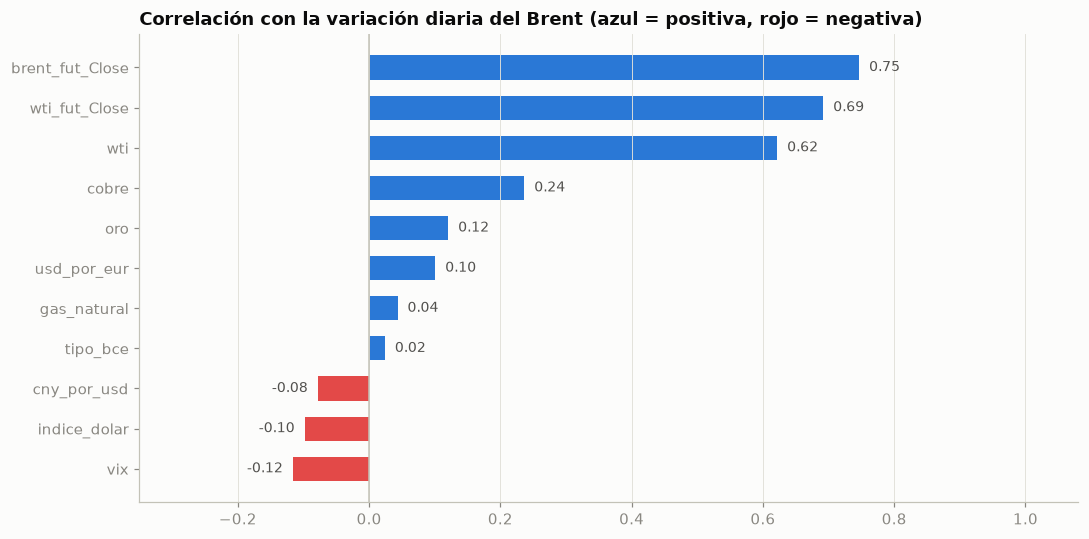

In [20]:
corr_dia = cambios.corr()["brent"].drop("brent").sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(corr_dia.index, corr_dia.values, height=0.6,
        color=[C["azul"] if v >= 0 else C["rojo"] for v in corr_dia])
for y, v in enumerate(corr_dia.values):
    ax.text(v + (0.015 if v >= 0 else -0.015), y, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", color=TINTA_2, fontsize=9)
ax.axvline(0, color=EJE, lw=1)
ax.set_xlim(-0.35, 1.08)
ax.grid(axis="y", visible=False)
ax.set_title("Correlación con la variación diaria del Brent (azul = positiva, rojo = negativa)")
plt.tight_layout()
plt.show()

### 6.2 ¿Alguna variable anticipa al Brent?

Correlación entre la variación del Brent hoy y la de cada variable **hace $k$ días**. Si fuera alta, esa variable sería un buen predictor.

In [21]:
anticipacion = pd.DataFrame({f"t-{k}": cambios[VARIABLES].shift(k).corrwith(cambios["brent"])
                             for k in range(1, 6)})
anticipacion.loc["brent (propio pasado)"] = [cambios["brent"].autocorr(k) for k in range(1, 6)]
anticipacion.round(3)

,t-1,t-2,t-3,t-4,t-5
wti,0.17,0.06,0.04,0.03,0.01
brent_fut_Close,0.14,-0.01,0.02,0.04,-0.00
wti_fut_Close,0.18,0.03,0.02,0.03,0.00
gas_natural,0.01,-0.00,0.00,-0.01,-0.01
tipo_bce,-0.03,0.03,-0.01,0.01,0.01
usd_por_eur,-0.02,-0.01,0.00,0.02,-0.01
cny_por_usd,-0.01,-0.00,0.01,-0.02,0.02
vix,-0.05,-0.03,-0.02,0.01,0.01
indice_dolar,-0.01,0.02,-0.00,-0.03,0.01
oro,0.03,0.01,-0.01,0.00,-0.03


### 6.3 ¿La relación es estable en el tiempo?

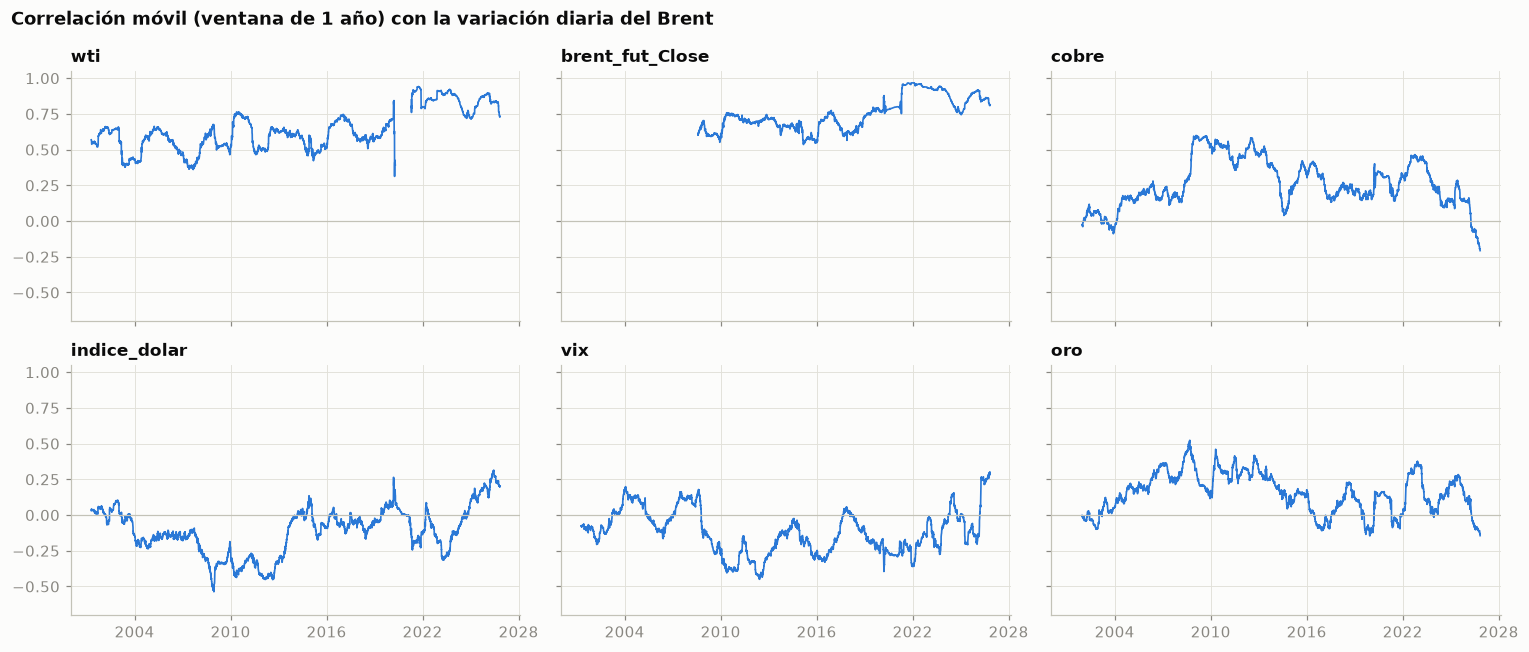

In [22]:
SELECCION = ["wti", "brent_fut_Close", "cobre", "indice_dolar", "vix", "oro"]
movil = pd.DataFrame({c: cambios[c].rolling(252).corr(cambios["brent"]) for c in SELECCION})

fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True, sharey=True)
for ax, col in zip(axes.flat, SELECCION):
    ax.plot(movil.index, movil[col], color=C["azul"], lw=1.1)
    ax.axhline(0, color=EJE, lw=0.8)
    ax.set_title(col, fontsize=11)
    ax.set_ylim(-0.7, 1.05)
    eje_años(ax, 6)
fig.suptitle("Correlación móvil (ventana de 1 año) con la variación diaria del Brent",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 6.4 Redundancia entre variables

Correlación mínima entre Open/High/Low/Close del futuro del Brent (niveles): 0.9978


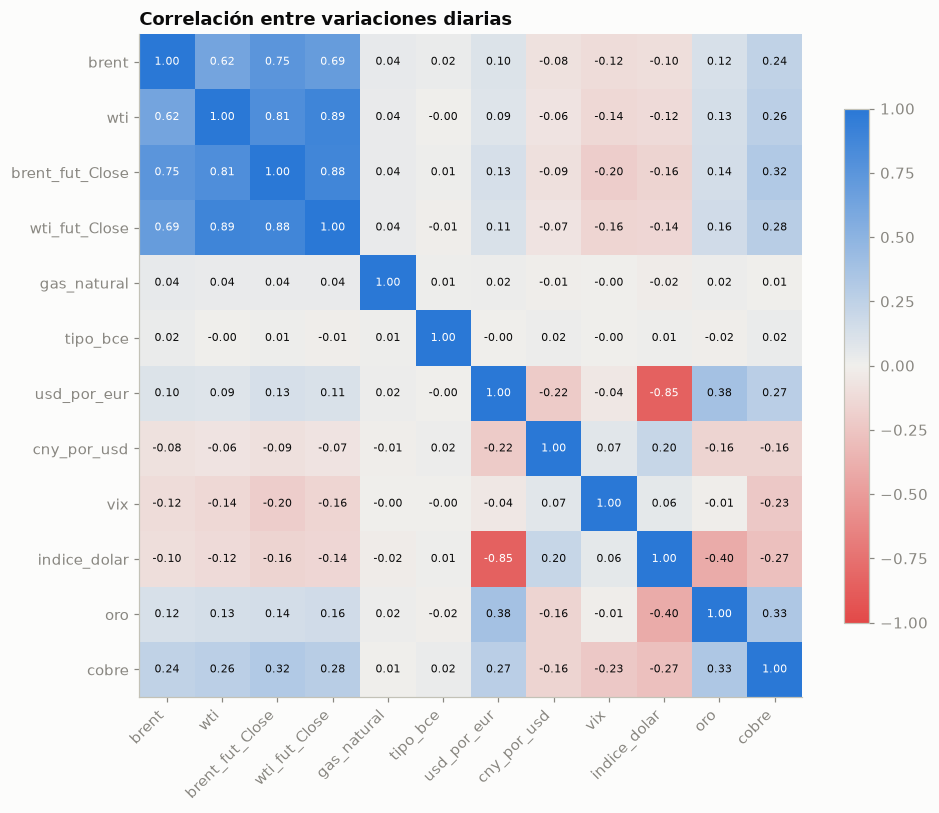

In [23]:
ohlc = dfb[["brent_fut_Open", "brent_fut_High", "brent_fut_Low", "brent_fut_Close"]].dropna()
print(f"Correlación mínima entre Open/High/Low/Close del futuro del Brent (niveles): "
      f"{ohlc.corr().values[np.triu_indices(4, 1)].min():.4f}")

matriz = cambios.corr()
divergente = LinearSegmentedColormap.from_list("divergente", [C["rojo"], "#f0efec", C["azul"]])
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(matriz, cmap=divergente, vmin=-1, vmax=1)
ax.set_xticks(range(len(matriz)), matriz.columns, rotation=45, ha="right")
ax.set_yticks(range(len(matriz)), matriz.index)
for i in range(len(matriz)):
    for j in range(len(matriz)):
        valor = matriz.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=7.5,
                color="#ffffff" if abs(valor) > 0.6 else TINTA)
ax.grid(False)
ax.set_title("Correlación entre variaciones diarias")
fig.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout()
plt.show()

> ### Conclusión de la sección 6
> - **En el mismo día**, lo que más se mueve con el Brent son los **futuros** (0,75 Brent; 0,69 WTI), el **WTI spot** (0,62) y, a distancia, el **cobre** (0,24). Tipos de cambio, oro, VIX e índice del dólar rondan ±0,1; el **gas natural** (Henry Hub, mercado de EE. UU.) y el **tipo del BCE**, ≈ 0.
> - **Hallazgo útil:** la variación de **ayer** del WTI y de los futuros anticipa algo la del Brent de **hoy** (0,14-0,18), mientras que el propio pasado del Brent no (−0,01). Lo más probable es un efecto de horario: el spot de la EIA se fija con el cierre de Londres y los mercados de EE. UU. cierran después, así que recogen noticias que el Brent incorpora al día siguiente. Puede ayudar sobre todo **a corto plazo**.
> - **Las relaciones no son estables:** la del cobre pasa de ≈ 0,6 (2009) a negativa en 2026; la del índice del dólar y la del VIX cambian de signo según el periodo.
> - **Mucha redundancia:** OHLC del futuro casi idénticos (ρ ≥ 0,998), WTI ≈ futuro del WTI (0,89), índice del dólar ≈ USD/EUR (−0,85).
>
> **Decisión, variables de entrada:** Brent + **WTI** + **cobre** + **oro** + **índice del dólar** + **VIX**, todas en variaciones.
> - Se descartan el gas natural y el tipo del BCE (sin relación diaria), los OHLC y volúmenes, y el USD/EUR (redundante con el índice del dólar).
> - Se descartan los **futuros**: el del Brent solo existe desde 2007 (obligaría a tirar 7 años) y el del WTI repite la información del WTI spot.
> - Como oro y cobre empiezan el 30/08/2000, la muestra empezará en esa fecha (se pierden 8 meses).

## 7. Los tres horizontes: el listón del modelo ingenuo

El modelo de referencia del enunciado es **«el precio futuro = el precio de hoy»**. Su error a $h$ días es simplemente lo que se mueve el precio en ese plazo: $e_t = P_{t+h} - P_t$. Cualquier red tiene que **mejorar ese error** para aportar valor.

Trabajamos con días reales de cotización: el Brent cotiza unas 243 sesiones al año, así que 5 sesiones son una semana, 63 algo más de 3 meses y 252 algo más de un año natural (≈ 12,5 meses).

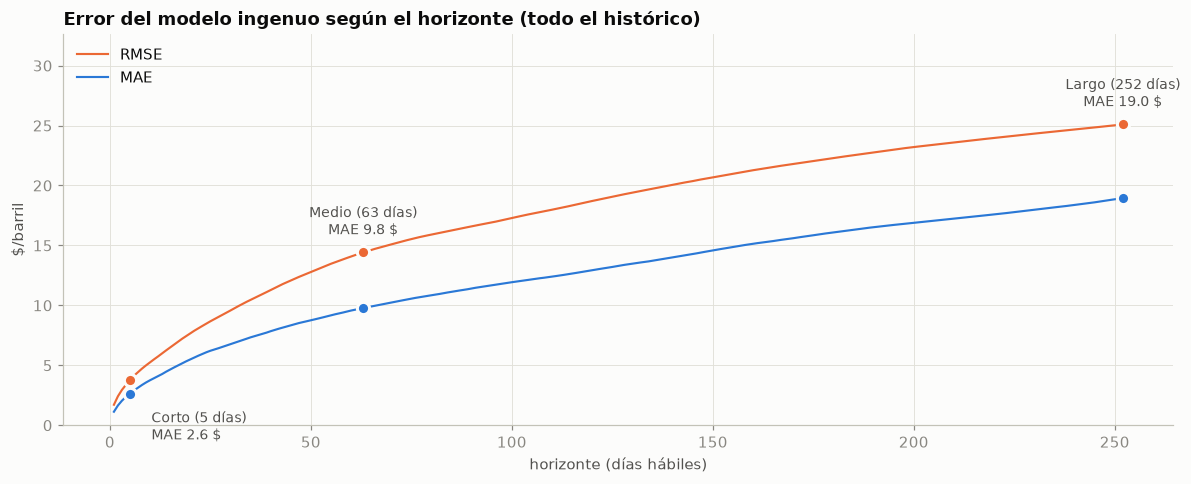

In [24]:
precio = brent.reset_index(drop=True)
fechas = brent.index

def errores_ingenuo(h):
    """Error del modelo ingenuo a h días, indexado por la fecha de origen."""
    return pd.Series((precio.shift(-h) - precio).values, index=fechas).dropna()

curva = pd.DataFrame({h: {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean())}
                      for h in range(1, 253) for e in [errores_ingenuo(h)]}).T

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(curva.index, curva["RMSE"], color=C["naranja"], label="RMSE")
ax.plot(curva.index, curva["MAE"], color=C["azul"], label="MAE")
for nombre, h in HORIZONTES.items():
    for metrica, color in [("MAE", C["azul"]), ("RMSE", C["naranja"])]:
        ax.plot(h, curva.loc[h, metrica], "o", ms=8, color=color, mec=FONDO, mew=2)
    corto = h == min(HORIZONTES.values())
    ax.annotate(f"{nombre}\nMAE {curva.loc[h, 'MAE']:.1f} $", (h, curva.loc[h, "MAE"] if corto else curva.loc[h, "RMSE"]),
                xytext=(14, -30) if corto else (0, 12), textcoords="offset points",
                ha="left" if corto else "center", fontsize=9, color=TINTA_2)
ax.set_xlabel("horizonte (días hábiles)")
ax.set_ylabel("$/barril")
ax.set_ylim(0, curva["RMSE"].max() * 1.3)
ax.legend(loc="upper left")
ax.set_title("Error del modelo ingenuo según el horizonte (todo el histórico)")
plt.tight_layout()
plt.show()

In [25]:
def resumen_horizontes(desde=None, hasta=None):
    filas = {}
    for nombre, h in HORIZONTES.items():
        e = errores_ingenuo(h).loc[desde:hasta]
        origen = brent.loc[e.index]
        cambio = e / origen                               # variación relativa P(t+h)/P(t) - 1
        filas[nombre] = {
            "orígenes": len(e),
            "MAE ($)": e.abs().mean(),
            "RMSE ($)": np.sqrt((e ** 2).mean()),
            "MAPE (%)": (cambio.abs() * 100).mean(),
            "% veces que sube": (e > 0).mean() * 100,
            "P10 variación (%)": cambio.quantile(0.10) * 100,
            "P90 variación (%)": cambio.quantile(0.90) * 100,
        }
    return pd.DataFrame(filas).T.astype({"orígenes": int})

print("Histórico completo")
display(resumen_horizontes())
print("Desde 2022 (periodo de test, ver sección 8)")
display(resumen_horizontes(desde="2022-01-01"))

Histórico completo


,orígenes,MAE ($),RMSE ($),MAPE (%),% veces que sube,P10 variación (%),P90 variación (%)
Corto (5 días),6496,2.65,3.78,4.17,53.76,-6.41,6.53
Medio (63 días),6438,9.77,14.41,15.30,57.07,-19.45,26.63
Largo (252 días),6249,18.95,25.09,30.87,57.55,-37.05,64.26


Desde 2022 (periodo de test, ver sección 8)


,orígenes,MAE ($),RMSE ($),MAPE (%),% veces que sube,P10 variación (%),P90 variación (%)
Corto (5 días),1218,3.99,5.74,4.47,50.66,-6.70,7.10
Medio (63 días),1160,11.94,17.44,14.40,43.19,-15.67,24.49
Largo (252 días),971,16.50,22.53,20.20,32.34,-24.57,44.89


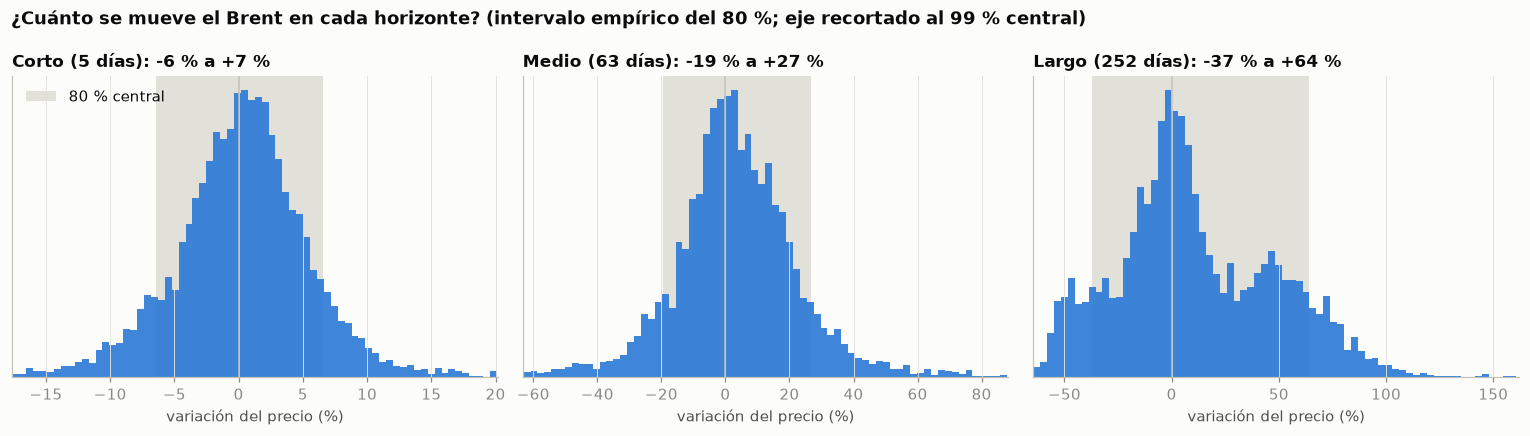

Periodos sin solapar disponibles en el histórico:
  Corto (5 días)     1300
  Medio (63 días)     103
  Largo (252 días)     25


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nombre, h) in zip(axes, HORIZONTES.items()):
    e = errores_ingenuo(h)
    cambio = e / brent.loc[e.index] * 100
    p10, p90 = cambio.quantile([0.10, 0.90])
    ax.axvspan(p10, p90, color=REJILLA, lw=0, label="80 % central")
    lim_inf, lim_sup = cambio.quantile([0.005, 0.995])
    ax.hist(cambio[cambio.between(lim_inf, lim_sup)], bins=70, color=C["azul"], alpha=0.9)
    ax.set_xlim(lim_inf, lim_sup)
    ax.axvline(0, color=EJE, lw=1)
    ax.set_title(f"{nombre}: {p10:+.0f} % a {p90:+.0f} %", fontsize=11)
    ax.set_xlabel("variación del precio (%)")
    ax.set_yticks([])
axes[0].legend(loc="upper left")
fig.suptitle("¿Cuánto se mueve el Brent en cada horizonte? (intervalo empírico del 80 %; eje recortado al 99 % central)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

print("Periodos sin solapar disponibles en el histórico:")
for nombre, h in HORIZONTES.items():
    print(f"  {nombre:<17} {len(brent) // h:>5}")

> ### Conclusión de la sección 7
>
> | Horizonte | MAE ingenuo | RMSE ingenuo | Error medio relativo | Intervalo 80 % de la variación |
> |---|---|---|---|---|
> | Corto (5 días) | 2,65 $ | 3,78 $ | 4,2 % | −6 % a +7 % |
> | Medio (63 días) | 9,77 $ | 14,41 $ | 15,3 % | −19 % a +27 % |
> | Largo (252 días) | 18,95 $ | 25,09 $ | 30,9 % | −37 % a +64 % |
>
> - El error crece aproximadamente con la raíz del horizonte. **En el periodo de test (2022-hoy)** el ingenuo comete un MAE de 3,99 $ / 11,94 $ / 16,50 $.
> - En el histórico el precio sube el 54-58 % de las veces, pero **en el test sube solo el 43 % de las veces a 63 días y el 32 % a 252 días**: la tendencia no es estable y un modelo que aprenda «siempre sube» fallaría en test.
> - A 252 días el histórico solo contiene **≈ 25 periodos sin solapar**: hay miles de ventanas, pero comparten casi el mismo futuro, así que la evaluación a largo plazo es frágil y hay que presentarla con prudencia.
>
> **Decisiones:**
> - La tabla comparativa mostrará la **mejora porcentual sobre el ingenuo**, calculada en el mismo periodo.
> - **Intervalo del 80 % en la app:** cuantiles 10-90 de los errores del modelo en validación, por horizonte, **en relación con la volatilidad reciente** (21 días). En la app se multiplican por la volatilidad del momento, así que la horquilla se ensancha en las crisis y se estrecha en calma.
> - Expectativa honesta: alguna mejora posible a corto plazo; a 63 y 252 días es probable que la red no bata al ingenuo, y el enunciado pide decirlo.

## 8. Particiones temporales

El enunciado **no fija fechas de corte**; solo pone reglas: **mismas particiones para las tres redes**, **validación walk-forward**, **sin mezclar fechas** y escalador ajustado **solo con train**. Además:

- Una muestra con origen en $t$ usa como objetivo el precio en $t+h$. Para no filtrar información, **el objetivo debe caer dentro del mismo bloque** que su origen. Al final de cada bloque se pierden, por tanto, $h$ orígenes.
- La ventana de entrada (60 días) sí puede tomar datos del bloque anterior: es pasado, no futuro.

> **Regla de oro:** la partición se elige **antes de entrenar** y con criterios fijados de antemano. Elegirla según los resultados del modelo (aunque sea en validación) sería escoger el examen más fácil, no la mejor partición, y daría resultados optimistas.

### 8.1 Comparación de particiones candidatas

Criterios: train con regímenes variados, validación con algún episodio de estrés, test reciente y representativo, y **suficientes años independientes** para evaluar el horizonte de 252 días, que es el más frágil.

In [27]:
CANDIDATAS = {
    "A": ("2018-12-31", "2022-12-31"),
    "B": ("2016-12-31", "2021-12-31"),
    "C": ("2019-12-31", "2022-12-31"),
    "D": ("2020-12-31", "2023-12-31"),
    "E": ("2017-12-31", "2021-12-31"),
    "F (70/15/15)": (brent.index[int(len(brent) * 0.70)], brent.index[int(len(brent) * 0.85)]),
}
# Fecha representativa de cada episodio de estrés
EPISODIOS = {"2008": "2008-10-15", "2014-16": "2015-06-01", "2020": "2020-04-15",
             "2022": "2022-04-15", "2026": "2026-06-01"}

def describir(serie):
    return f"{serie.index[0]:%m/%Y}-{serie.index[-1]:%m/%Y}"

comparacion = {}
for nombre, (fin_train, fin_val) in CANDIDATAS.items():
    fin_train, fin_val = pd.Timestamp(fin_train), pd.Timestamp(fin_val)
    train = brent[brent.index <= fin_train]
    val = brent[(brent.index > fin_train) & (brent.index <= fin_val)]
    test = brent[brent.index > fin_val]
    episodios_en = lambda ini, fin: ", ".join(
        e for e, f in EPISODIOS.items() if ini < pd.Timestamp(f) <= fin) or "-"
    comparacion[nombre] = {
        "train": describir(train), "validación": describir(val), "test": describir(test),
        "crisis en val": episodios_en(fin_train, fin_val),
        "crisis en test": episodios_en(fin_val, pd.Timestamp.max),
        "años indep. 252 (val)": (len(val) - 1) // 252,
        "años indep. 252 (test)": (len(test) - 1) // 252,
        "volatilidad val": f"{ret.loc[val.index[1:]].std() * np.sqrt(252):.0%}",
        "volatilidad test": f"{ret.loc[test.index[1:]].std() * np.sqrt(252):.0%}",
    }
pd.DataFrame(comparacion).T

,train,validación,test,crisis en val,crisis en test,años indep. 252 (val),años indep. 252 (test),volatilidad val,volatilidad test
A,01/2000-12/2018,01/2019-12/2022,01/2023-11/2026,"2020, 2022",2026,4,3,66%,42%
B,01/2000-12/2016,01/2017-12/2021,01/2022-11/2026,2020,"2022, 2026",5,4,58%,44%
C,01/2000-12/2019,01/2020-12/2022,01/2023-11/2026,"2020, 2022",2026,3,3,74%,42%
D,01/2000-12/2020,01/2021-12/2023,01/2024-11/2026,2022,2026,2,2,39%,45%
E,01/2000-12/2017,01/2018-12/2021,01/2022-11/2026,2020,"2022, 2026",4,4,64%,44%
F (70/15/15),01/2000-02/2019,02/2019-12/2022,12/2022-11/2026,"2020, 2022",2026,3,3,67%,42%


**Decisión: partición E** (train 2000-2017 · validación 2018-2021 · test 2022-hoy).

| Criterio | A (2023-hoy) | E (2022-hoy) |
|---|---|---|
| Solidez del test a 252 días (años independientes) | 3 | **4** |
| Crisis en el test | 2026 | **2022 y 2026** |
| Validación con estrés | 2020 y 2022 | 2018 y 2020 |
| Train con regímenes variados | sí | sí (un año menos) |
| Parecido validación/test | similar | similar |

- **D** y **C** se descartan porque dejan pocos años independientes (2-3) para validar o examinar el largo plazo.
- **F** es casi igual que A, pero corta a mitad de año.
- **B** recorta más el train sin ganar nada frente a E.
- A y E son las dos buenas opciones. El criterio que las separa es la **solidez del test en el horizonte más difícil** (4 años independientes frente a 3), reforzado porque E incluye las dos últimas crisis del precio.

**Prueba de robustez (pendiente):** al terminar, se repetirá la evaluación con la partición A. Si las conclusiones se mantienen (qué red gana y en qué horizontes aporta), el resultado es más creíble. Esa repetición sirve solo para comprobar, no para elegir.

### 8.2 Partición elegida

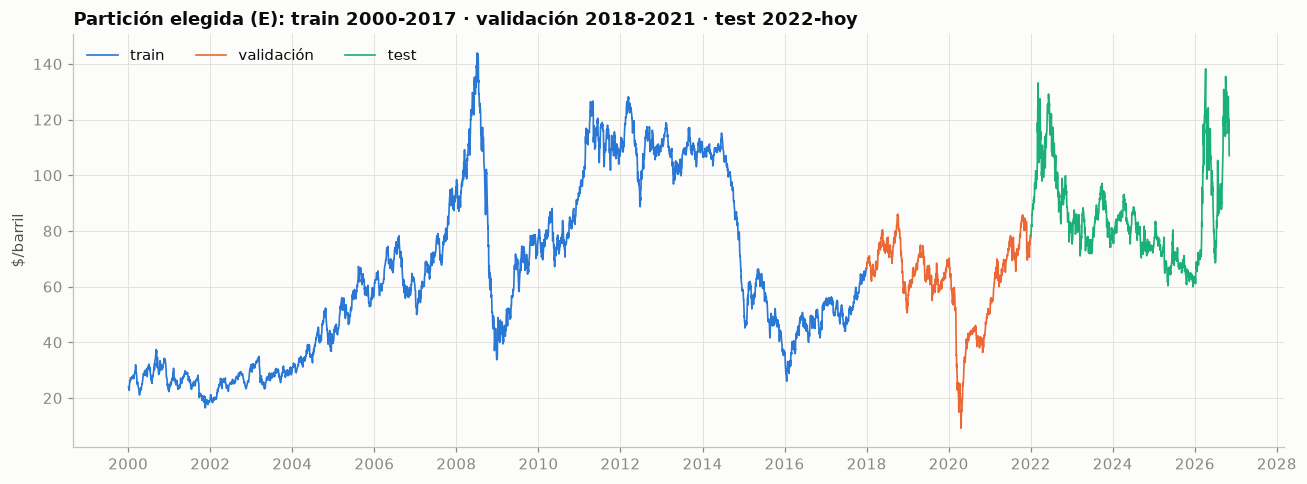

,desde,hasta,días,mín ($),máx ($),volatilidad anual,orígenes h=5,orígenes h=63,orígenes h=252
train,2000-01-04,2017-12-29,4261,16.51,143.95,37%,4256,4198,4009
validación,2018-01-02,2021-12-31,1017,9.12,86.07,64%,1012,954,765
test,2022-01-03,2026-11-03,1223,59.93,138.21,44%,1218,1160,971


In [28]:
BLOQUES = {"train": ("2000-01-01", "2017-12-31"),
           "validación": ("2018-01-01", "2021-12-31"),
           "test": ("2022-01-01", None)}
COLOR_BLOQUE = {"train": C["azul"], "validación": C["naranja"], "test": C["aqua"]}

fig, ax = plt.subplots(figsize=(12, 4.5))
filas = {}
for nombre, (ini, fin) in BLOQUES.items():
    tramo = brent.loc[ini:fin]
    ax.plot(tramo.index, tramo, color=COLOR_BLOQUE[nombre], lw=1.1, label=nombre)
    vol = np.log(tramo).diff().std() * np.sqrt(252)
    filas[nombre] = {"desde": tramo.index[0].date(), "hasta": tramo.index[-1].date(), "días": len(tramo),
                     "mín ($)": tramo.min(), "máx ($)": tramo.max(), "volatilidad anual": f"{vol:.0%}",
                     **{f"orígenes h={h}": max(len(tramo) - h, 0) for h in HORIZONTES.values()}}
ax.legend(loc="upper left", ncol=3)
ax.set_ylabel("$/barril")
eje_años(ax)
ax.set_title("Partición elegida (E): train 2000-2017 · validación 2018-2021 · test 2022-hoy")
plt.tight_layout()
plt.show()
pd.DataFrame(filas).T

### 8.3 Walk-forward dentro de train + validación

Cada pliegue entrena con todo lo anterior a un año de validación y evalúa en ese año, como se haría en la realidad. Al final se reentrena con train + validación y se evalúa una sola vez en test.

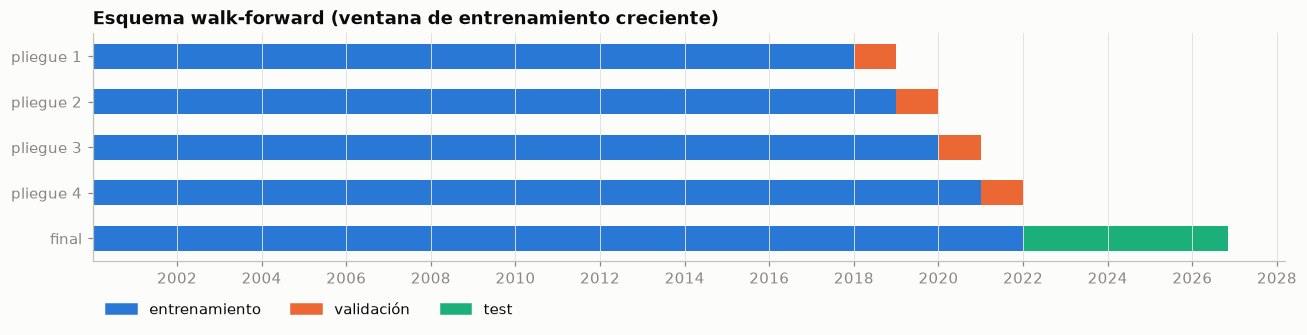

,entrena hasta,valida,orígenes h=5,orígenes h=63,orígenes h=252
pliegue 1,2017-12-31,2018,252,252,252
pliegue 2,2018-12-31,2019,257,257,257
pliegue 3,2019-12-31,2020,255,255,255
pliegue 4,2020-12-31,2021,248,190,1


In [29]:
FIN_VALIDACION = pd.Timestamp("2021-12-31")
INICIO_TEST = pd.Timestamp("2022-01-01")
pliegues = [2018, 2019, 2020, 2021]

fig, ax = plt.subplots(figsize=(12, 3.2))
filas = {}
for i, año in enumerate(pliegues):
    ini_val, fin_val = pd.Timestamp(f"{año}-01-01"), pd.Timestamp(f"{año}-12-31")
    y = len(pliegues) - i
    ax.barh(y, mdates.date2num(ini_val) - mdates.date2num(fechas[0]), left=mdates.date2num(fechas[0]),
            height=0.55, color=COLOR_BLOQUE["train"])
    ax.barh(y, 365, left=mdates.date2num(ini_val), height=0.55, color=COLOR_BLOQUE["validación"])
    # orígenes válidos: dentro del año y con el objetivo antes de que empiece el test
    pos = np.flatnonzero((fechas >= ini_val) & (fechas <= fin_val))
    limite = np.searchsorted(fechas, FIN_VALIDACION, side="right") - 1
    filas[f"pliegue {i + 1}"] = {"entrena hasta": (ini_val - pd.Timedelta(days=1)).date(), "valida": año,
                                 **{f"orígenes h={h}": int((pos + h <= limite).sum())
                                    for h in HORIZONTES.values()}}
ax.barh(0, mdates.date2num(INICIO_TEST) - mdates.date2num(fechas[0]),
        left=mdates.date2num(fechas[0]), height=0.55, color=COLOR_BLOQUE["train"])
ax.barh(0, mdates.date2num(fechas[-1]) - mdates.date2num(INICIO_TEST),
        left=mdates.date2num(INICIO_TEST), height=0.55, color=COLOR_BLOQUE["test"])
ax.set_yticks(range(len(pliegues) + 1), ["final"] + [f"pliegue {i}" for i in range(len(pliegues), 0, -1)])
ax.xaxis_date()
eje_años(ax)
ax.grid(axis="y", visible=False)
marcas = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOR_BLOQUE.values()]
ax.legend(marcas, ["entrenamiento", "validación", "test"], ncol=3, loc="upper left", bbox_to_anchor=(0, -0.12))
ax.set_title("Esquema walk-forward (ventana de entrenamiento creciente)")
plt.tight_layout()
plt.show()
pd.DataFrame(filas).T

> ### Conclusión de la sección 8
> **Partición elegida: E**, frente a la alternativa A, por dar un test más sólido en el horizonte más difícil (4 años independientes frente a 3) y por incluir las dos últimas crisis del precio.
> - **Train 2000-2017** (4.261 días): incluye 2008 y 2014-2016, y su máximo (143,95 $) supera todo lo posterior, así que el escalador no verá valores fuera de rango.
> - **Validación 2018-2021** (1.017 días): caída de finales de 2018, pandemia y recuperación de 2021, con una volatilidad del 64 %. Elegir hiperparámetros aquí favorece modelos robustos.
> - **Test 2022-hoy** (1.223 días): guerra de Ucrania, años tranquilos y pico de 2026; 971 orígenes a 252 días.
> - **Walk-forward con 4 pliegues anuales (2018-2021).** A 252 días el último pliegue casi no tiene orígenes válidos (su objetivo caería en el test), así que el largo plazo se valida con 3.
> - En cada pliegue se **purga** el final del entrenamiento: se eliminan las muestras de train cuyo objetivo cae ya en el año de validación.
>
> **Decisión:** usar la partición E para las tres redes y ajustar el escalador solo con el train de cada pliegue. Al final, **prueba de robustez con la partición A**.

## 9. Conclusiones y decisiones para el modelado

| # | Tema | Decisión |
|---|---|---|
| 1 | **Datos** | Calendario real del Brent; muestra desde el 30/08/2000; «último precio» = último dato real de la EIA. |
| 2 | **Objetivo** | Variación logarítmica del Brent a 5, 63 y 252 sesiones; el precio se reconstruye a partir de ella. |
| 3 | **Variables** | Brent, WTI, cobre, oro, índice del dólar y VIX, en variaciones. WTI del 20/04/2020 sustituido por el valor anterior. |
| 4 | **Preprocesamiento** | Entradas recortadas entre sus percentiles 1 y 99 y escaladas, ambas cosas ajustadas solo con train; pérdida Huber al entrenar. Ventanas de 20, 60 y 120 días probadas en validación; la elegida es la misma para las tres redes. |
| 5 | **Particiones** | Partición E: train 2000-2017 · validación walk-forward 2018-2021 (4 pliegues, con purga) · test 2022-hoy, usado una sola vez. Prueba de robustez final con la partición A (test 2023-hoy). |
| 6 | **Comparativa** | RNN, LSTM y GRU con los mismos datos, ventana, particiones y una rejilla de hiperparámetros pequeña e igual para las tres. |
| 7 | **Métricas** | MSE, MAE, RMSE, mejora frente al ingenuo, % de acierto en la dirección, nº de parámetros y tiempo de entrenamiento. |
| 8 | **Incertidumbre** | Intervalo del 80 % con los cuantiles 10-90 de los errores de validación de cada horizonte, relativos a la volatilidad reciente: la horquilla se adapta al riesgo del momento. |
| 9 | **Aplicación** | Tabla de eventos para el gráfico histórico; textos que avisen de que los shocks externos (geopolítica, OPEP+, crisis) invalidan la predicción. |

**Qué esperar:** la variación del Brent es casi impredecible a partir de su pasado y tiene colas muy gruesas. Lo razonable es una mejora pequeña a corto plazo y resultados similares o peores que el ingenuo a 63 y 252 días. El valor de la aplicación estará en **cuantificar el riesgo** (rango de precios plausible) y en explicarlo bien, más que en acertar el precio exacto.

**Pendiente:** documentar la causa del pico de 2026. La cesta OPEP no está disponible en el dataset y se indicará como limitación.